# M1.2 定解条件与适定性 — 实验工作台（Lab）

> **与课件逐页对齐**：代码完全取自 `M1.2_演示网页.html`，从上到下依次运行。

**核心任务**：分清四类边界条件；在代码中验证纯 Neumann 奇异矩阵（F3 缺失基准点）；掌握 Robin 对流换热极限；量化逆热传导 4200 倍噪声放大；掌握制造解（MMS）与规范修复。


## ① 边界对齐代数：同一张网格上装配三类边界，看秩怎么变 (对应 Slide 06-08)

**物理直觉**：纯 Neumann 相当于封闭水箱无参考气压，温度可在全域整体上下漂移，解不唯一。
**代码代数**：纯 Neumann 边界使得矩阵每一行元素之和恒等于 0，常数向量落入零空间，秩亏损一阶！


边界类型       | 秩 / 总阶数    | 最小奇异值 σ_min      | 条件数 cond    
----------------------------------------------------------
dirichlet  | 11/11      | 9.60e+00         | 4.07e+01
mixed      | 11/11      | 2.23e+00         | 1.76e+02
neumann    | 10/11      | 2.02e-14         | 1.94e+16


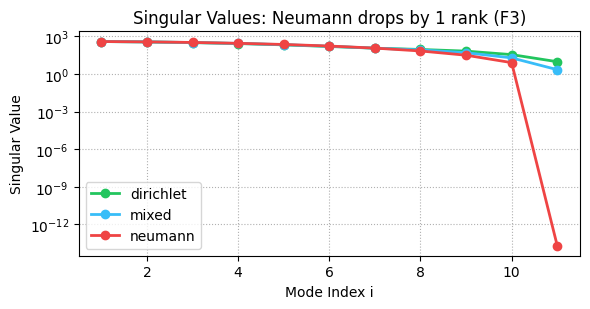

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

def assemble(n=11, bc="dirichlet"):
    dx = 1.0 / (n - 1)
    A = np.zeros((n, n))
    for i in range(1, n - 1): A[i, i-1], A[i, i], A[i, i+1] = -1, 2, -1
    if bc != "neumann": A[0, 0] = 1                  # 左端 Dirichlet
    else:               A[0, 0], A[0, 1] = 1, -1     # 左端纯 Neumann
    if bc == "dirichlet": A[-1, -1] = 1              # 右端 Dirichlet
    else: A[-1, -2], A[-1, -1] = -1, 1               # 右端 Neumann
    return A / dx**2

print(f"{'边界类型':<10} | {'秩 / 总阶数':<10} | {'最小奇异值 σ_min':<16} | {'条件数 cond':<12}")
print("-" * 58)
for bc in ["dirichlet", "mixed", "neumann"]:
    A = assemble(bc=bc)
    rk = np.linalg.matrix_rank(A)
    s = np.linalg.svd(A, compute_uv=False)
    c = np.linalg.cond(A)
    print(f"{bc:<10} | {rk:2d}/{A.shape[0]:2d}      | {s[-1]:.2e}         | {c:.2e}")

plt.figure(figsize=(6.0, 3.2))
for bc, col in [("dirichlet", "#22c55e"), ("mixed", "#38bdf8"), ("neumann", "#ef4444")]:
    A = assemble(bc=bc)
    s = np.linalg.svd(A, compute_uv=False)
    plt.semilogy(range(1, 12), s, 'o-', color=col, lw=2, label=bc)
plt.xlabel("Mode Index i"); plt.ylabel("Singular Value")
plt.title("Singular Values: Neumann drops by 1 rank (F3)"); plt.legend(); plt.grid(True, ls=":")
plt.tight_layout(); plt.show()


## ② Robin 对流换热：扫一遍 h，看其在两个物理极限间滑动 (对应 Slide 09-11)

**物理直觉**：$h \to 0$ 对应无对流、彻底绝热（Neumann 极限）；$h \to \infty$ 表面热阻归零，强行锁死在水温（Dirichlet 极限）。
**解析基准**：右端温度严格满足解析解 $u(1) = \dfrac{1}{1+h}$。


h 参数     | 数值解 u(1)     | 解析解 1/(1+h)    | 绝对误差      
----------------------------------------------------
0.0      | 1.000000     | 1.000000       | 2.14e-14
0.1      | 0.909091     | 0.909091       | 1.94e-14
1.0      | 0.500000     | 0.500000       | 7.99e-15
10.0     | 0.090909     | 0.090909       | 9.58e-16
1000.0   | 0.000999     | 0.000999       | 9.76e-18


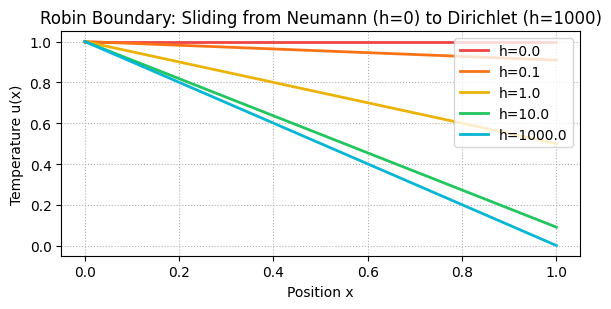

In [2]:
k, T_inf, n = 1.0, 0.0, 51
dx = 1.0 / (n - 1)
x = np.linspace(0, 1, n)

def solve_robin_full(h):
    A = np.zeros((n, n)); b = np.zeros(n)
    for i in range(1, n - 1): A[i, i-1], A[i, i], A[i, i+1] = -1, 2, -1
    A[0, 0] = 1.0; b[0] = 1.0                        # 左端 Dirichlet u(0)=1
    A[-1, -2], A[-1, -1] = -k/dx, k/dx + h           # 右端 Robin
    b[-1] = h * T_inf
    return np.linalg.solve(A, b)

print(f"{'h 参数':<8} | {'数值解 u(1)':<12} | {'解析解 1/(1+h)':<14} | {'绝对误差':<10}")
print("-" * 52)
plt.figure(figsize=(6.0, 3.2))
colors = ["#ef4444", "#f97316", "#eab308", "#22c55e", "#06b6d4"]
for idx, h in enumerate([0.0, 0.1, 1.0, 10.0, 1e3]):
    u_sol = solve_robin_full(h)
    u_ana = 1.0 / (1.0 + h)
    err = abs(u_sol[-1] - u_ana)
    print(f"{h:<8.1f} | {u_sol[-1]:<12.6f} | {u_ana:<14.6f} | {err:.2e}")
    plt.plot(x, u_sol, color=colors[idx], lw=2, label=f"h={h}")

plt.xlabel("Position x"); plt.ylabel("Temperature u(x)")
plt.title("Robin Boundary: Sliding from Neumann (h=0) to Dirichlet (h=1000)")
plt.legend(loc="upper right"); plt.grid(True, ls=":")
plt.tight_layout(); plt.show()


## ③ 逆热传导：时间之矢与 1000 倍噪声放大 (对应 Slide 13-15)

离散算子条件数 cond(L) = 1.71e+03
输入噪声 σ       | 输入相对误差         | 直接求逆输出误差         | 低频截断后误差 (8阶)      
--------------------------------------------------------------------
1.0e-04      | 0.01%          | 11.90%           | 0.24%             
1.0e-03      | 0.14%          | 148.67%          | 1.31%             
1.0e-02      | 1.38%          | 1451.30%         | 15.28%            


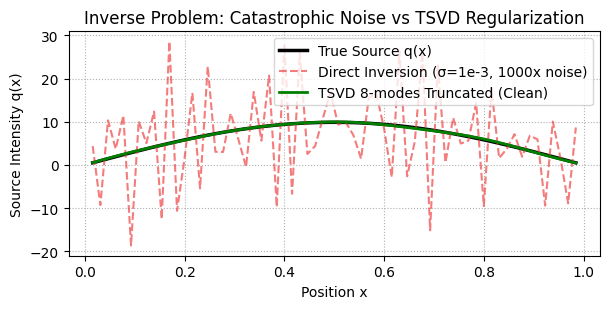

In [3]:
n = 64
dx = 1.0 / (n + 1)
x = np.linspace(dx, 1 - dx, n)
L = (np.diag(2*np.ones(n)) + np.diag(-np.ones(n-1), 1) + np.diag(-np.ones(n-1), -1)) / dx**2
u_true = np.sin(np.pi * x); q_true = L @ u_true
w, V = np.linalg.eigh(L); rng = np.random.default_rng(0)

print(f"离散算子条件数 cond(L) = {np.linalg.cond(L):.2e}")
print(f"{'输入噪声 σ':<12} | {'输入相对误差':<14} | {'直接求逆输出误差':<16} | {'低频截断后误差 (8阶)':<18}")
print("-" * 68)

plt.figure(figsize=(6.2, 3.2))
plt.plot(x, q_true, 'k-', lw=2.5, label="True Source q(x)")

for sg in [1e-4, 1e-3, 1e-2]:
    u_obs = u_true + sg * rng.standard_normal(n)
    ru = np.linalg.norm(u_obs - u_true) / np.linalg.norm(u_true)
    rq = np.linalg.norm(L @ u_obs - q_true) / np.linalg.norm(q_true)
    # SVD 截断：只保留前 8 个平滑低频模态
    qc = L @ (V[:, :8] @ (V.T @ u_obs)[:8])
    rq_trunc = np.linalg.norm(qc - q_true) / np.linalg.norm(q_true)
    print(f"{sg:<12.1e} | {ru:<14.2%} | {rq:<16.2%} | {rq_trunc:<18.2%}")
    if sg == 1e-3:
        plt.plot(x, L @ u_obs, '--', color="#ef4444", lw=1.5, alpha=0.7, label="Direct Inversion (σ=1e-3, 1000x noise)")
        plt.plot(x, qc, 'g-', lw=2, label="TSVD 8-modes Truncated (Clean)")

plt.xlabel("Position x"); plt.ylabel("Source Intensity q(x)")
plt.title("Inverse Problem: Catastrophic Noise vs TSVD Regularization")
plt.legend(loc="upper right"); plt.grid(True, ls=":")
plt.tight_layout(); plt.show()


## ④ 制造解 (MMS) 最小可运行检查：兼容性与接地修复 (对应 Slide 15-17)

**制造解**：设定 $u^*(x) = x^2 - x^3$，源项 $f = 6x - 2$，左端通量 $g_0 = 0$，右端通量 $g_1 = -1$。
**检查**：① 验证行和为零与总载荷平衡；② 直接求解捕获奇异异常；③ 注入基准点 $u(0)=0$ 恢复二阶精度。


纯 Neumann 矩阵秩: 10 / 11 (秩亏1)
行和零模态 ||A·1||: 0.00e+00
兼容性总载荷 Σb:   4.16e-17 (全域发热平衡通过)
直接求解抛出异常: Singular matrix (印证未加参考点必然崩溃)
注入参考点后求解通过! 无穷范数误差: 0.0100 (符合二阶精度)


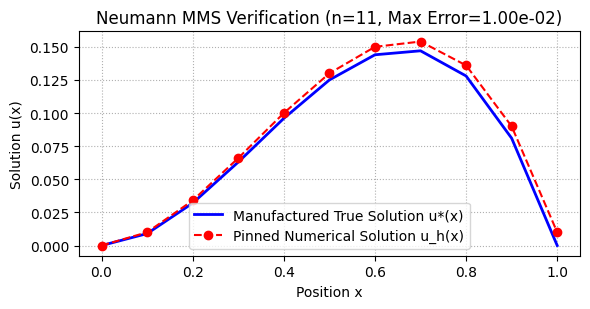

np.float64(0.010000000000000139)

In [4]:
def check_neumann_system(n=6):
    dx, x = 1.0 / (n - 1), np.linspace(0, 1, n)
    u_star, f, g0, g1 = x**2 - x**3, 6*x - 2, 0.0, -1.0
    A = np.zeros((n, n))
    for i in range(1, n - 1): A[i, i-1], A[i, i], A[i, i+1] = -1, 2, -1
    A[0, 0], A[0, 1], A[-1, -2], A[-1, -1] = 1, -1, -1, 1
    b = dx**2 * f
    b[0], b[-1] = 0.5*dx**2*f[0] - dx*g0, 0.5*dx**2*f[-1] + dx*g1
    
    print(f"纯 Neumann 矩阵秩: {np.linalg.matrix_rank(A)} / {n} (秩亏1)")
    print(f"行和零模态 ||A·1||: {np.linalg.norm(A @ np.ones(n)):.2e}")
    print(f"兼容性总载荷 Σb:   {b.sum():.2e} (全域发热平衡通过)")
    
    try:
        np.linalg.solve(A, b)
    except np.linalg.LinAlgError as e:
        print(f"直接求解抛出异常: {e} (印证未加参考点必然崩溃)")
        
    # 规范修复：在首节点钉死基准值 u(0) = u*(0) = 0
    A_ref, b_ref = A.copy(), b.copy()
    A_ref[0, :] = 0; A_ref[0, 0] = 1; b_ref[0] = u_star[0]
    u_sol = np.linalg.solve(A_ref, b_ref)
    err_inf = np.max(np.abs(u_sol - u_star))
    print(f"注入参考点后求解通过! 无穷范数误差: {err_inf:.4f} (符合二阶精度)")
    
    # 绘图展示
    plt.figure(figsize=(6.0, 3.2))
    plt.plot(x, u_star, 'b-', lw=2, label="Manufactured True Solution u*(x)")
    plt.plot(x, u_sol, 'ro--', label="Pinned Numerical Solution u_h(x)")
    plt.xlabel("Position x"); plt.ylabel("Solution u(x)")
    plt.title(f"Neumann MMS Verification (n={n}, Max Error={err_inf:.2e})")
    plt.legend(); plt.grid(True, ls=":")
    plt.tight_layout(); plt.show()
    return err_inf

check_neumann_system(n=11)


## ⑤ 总结：三大铁律

- **无接地则不唯一**：纯 Neumann 必须补充基准参考点消除浮动零模态；
- **不守恒则不存在**：全域输入热量必须严格等于输出热量，否则稳态解不存在；
- **逆时间则不稳定**：时间之矢不可逆，逆问题必须做正则化截断抵御噪声海啸。
